# Turtle Breakout 17 — BTC-USD daily since 2014: does the edge predate 2020, and does it survive the bear markets?

Pre-registration: `discussions/Turtle_Breakout/019_claude_tb17_preregistration.md`. Code: `turtle_btc_history.py`; data: Yahoo `BTC-USD` (downloaded on the first run if missing).

One account, TB 01 rules (2% of HWM per trade, ≤ 3× notional), long and long + reverse, daily bars with O→H→L→C fills, 6 bp per side.
**Decision window PRE = 2014-09-17 → 2019-12-31** (never used before). **G1:** real − random mean R ≥ 0.48R (97.5% quantile on driftless BTC-like series). **G2:** Calmar(long + reverse) − Calmar(long) bootstrap lower bound > 0.
FULL (2014 → now) and POST (2020 → now) reported, with results by market regime.

Environment: `TB17_DATA` (default `<parent of DERIBIT_DATA_ROOT>/Stocks/tb17/btc_daily.parquet`), `TB17_SYNTHETIC=1`.

In [1]:
import os, sys, json, subprocess, tempfile, warnings, platform
from dataclasses import replace
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 200)
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'src' / 'data_engineering').is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src')); load_dotenv(ROOT / '.env')
from data_engineering.modeling import turtle_breakout as tb, turtle_reverse as tr, turtle_stocks as tk, turtle_stock_accounts as ta, turtle_btc_history as bh, turtle_oos as to

SYNTHETIC = os.getenv('TB17_SYNTHETIC', '0') == '1'
BP = bh.BParams(); AP = replace(ta.AParams(), status=BP.status)
P = replace(tb.Params(), min_bar_share=0.0, funding=False, fee=BP.side_cost - tb.Params().slip)
RP = replace(tr.RParams(), side_cost=BP.side_cost)
OP = replace(to.OParams(), n_tests=BP.n_tests)
if SYNTHETIC:
    OUT = Path(tempfile.mkdtemp(prefix='tb17-')) / '17'; BP = replace(BP, n_null=50)
    d, _ = tk.synthetic_daily(4425, seed=17, vol=0.04, gap=0.0, steps=48, drift=0.001); d.index = pd.date_range('2014-09-17', periods=len(d), freq='D')
    DAILY = d
else:
    OUT = ROOT / 'notebooks' / 'Turtle_Breakout' / '17'
    root = Path(os.environ['DERIBIT_DATA_ROOT']).parent
    DATA_FILE = Path(os.environ.get('TB17_DATA', str(root / 'Stocks' / 'tb17' / 'btc_daily.parquet')))
    if not DATA_FILE.exists():
        sys.path.insert(0, str(ROOT / 'tools')); import download_tb17_btc as dl
        DATA_FILE = dl.download(DATA_FILE.parent)
    RAW = pd.read_parquet(DATA_FILE); RAW['date'] = pd.to_datetime(RAW['date']).dt.tz_localize(None).dt.normalize()
    DAILY = RAW.set_index('date')[['open', 'high', 'low', 'close']].sort_index()
    DAILY = DAILY[~DAILY.index.duplicated()].dropna(); DAILY = DAILY[(DAILY > 0).all(axis=1)]
OUT.mkdir(parents=True, exist_ok=True)
env = os.environ.copy(); env['PYTHONPATH'] = str(ROOT / 'src') + os.pathsep + env.get('PYTHONPATH', '')
chk = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-p', 'test_turtle_btc_history.py'], cwd=str(ROOT), env=env, capture_output=True, text=True)
print(chk.stderr.strip().splitlines()[-1]); assert chk.returncode == 0
print('BTC-USD', DAILY.index[0].date(), '->', DAILY.index[-1].date(), len(DAILY), 'days; missing calendar days:',
      len(pd.date_range(DAILY.index[0], DAILY.index[-1], freq='D')) - len(DAILY))
print(json.dumps(bh.registration(BP), indent=1, default=str))

1 tickers, 2014-01-01 -> 2026-10-28
  1/1: 1 tickers with data
saved 4,424 rows, 1 tickers; missing: 0 -> D:\MarketData\Stocks\tb17\stocks_daily.parquet
renamed -> D:\MarketData\Stocks\tb17\btc_daily.parquet
OK
BTC-USD 2014-09-17 -> 2026-10-27 4424 days; missing calendar days: 0
{
 "side_cost": 0.0006,
 "side_cost_high": 0.0015,
 "n_null": 1000,
 "alpha": 0.05,
 "n_tests": 2,
 "seed": 20261029,
 "status": "PREREGISTERED_TB019",
 "version": "TB17-0.1.0",
 "windows": {
  "PRE": [
   "2014-09-17",
   "2019-12-31"
  ],
  "FULL": [
   "2014-09-17",
   null
  ],
  "POST": [
   "2020-01-01",
   null
  ]
 },
 "threshold_R": {
  "PRE": 0.48,
  "FULL": 0.33,
  "POST": null
 },
 "regimes": [
  [
   "2014-09-17",
   "2015-01-14",
   "bear 2014"
  ],
  [
   "2015-01-15",
   "2015-10-31",
   "base 2015"
  ],
  [
   "2015-11-01",
   "2017-12-17",
   "bull 2015-17"
  ],
  [
   "2017-12-18",
   "2018-12-15",
   "bear 2018"
  ],
  [
   "2018-12-16",
   "2021-11-10",
   "bull 2019-21"
  ],
  [
   "2021-1

## 1. The three windows

In [2]:
RES, ROWS = {}, []
rng = np.random.default_rng(BP.seed)
for w, (a, b) in bh.WINDOWS.items():
    r = bh.run_window(DAILY, a, b, P, RP, AP, BP.n_null, rng); RES[w] = r
    rh = bh.run_window(DAILY, a, b, P, RP, AP, 0, rng, cost=BP.side_cost_high); RES[w + '_cost'] = rh
    m = {v: tk.metrics(r[v], P.start_equity) for v in ('long', 'long_rev', 'hold')}
    mh = {v: tk.metrics(rh[v], P.start_equity) for v in ('long', 'long_rev')}
    real = r['R_long'].mean(); nm = r['null_means']
    rev = r['trades'].query("kind == 'reverse'").R
    ROWS.append({'window': w, 'start': str(r['long'].index[0].date()), 'end': str(r['long'].index[-1].date()), 'long_trades': len(r['R_long']),
                 'mean_R_long': real, 'random_mean_R': nm.mean(), 'diff_R': real - nm.mean(), 'threshold_R': bh.THRESHOLD_R[w],
                 'empirical_p': float((1 + np.sum(nm >= real)) / (1 + len(nm))), 'reverse_trades': len(rev), 'mean_R_reverse': rev.mean(),
                 **{f'{v}_{k}': m[v][k] for v in m for k in ('cagr', 'max_dd', 'calmar', 'sharpe')},
                 **{f'{v}_cagr_15bp': mh[v]['cagr'] for v in mh}, 'mean_gross': r['mean_gross']})
WIN = pd.DataFrame(ROWS).set_index('window'); display(WIN.T.round(4))

window,PRE,FULL,POST
start,2014-10-17,2014-10-17,2020-01-31
end,2019-12-31,2026-10-27,2026-10-27
long_trades,31,88,57
mean_R_long,3.301444,1.814286,0.937235
random_mean_R,1.538861,0.89377,0.450013
diff_R,1.762583,0.920516,0.487222
threshold_R,0.48,0.33,NaN
empirical_p,0.000999,0.000999,0.007992
reverse_trades,11,45,34
mean_R_reverse,0.130644,0.184623,0.202097


## 2. Decision (PRE)

In [3]:
pre = WIN.loc['PRE']
g1 = bool(pre.diff_R >= bh.THRESHOLD_R['PRE'])
B = to.gate_calmar(RES['PRE']['long_rev'], RES['PRE']['long'], P.start_equity, OP, BP.seed + 1, ann=365.25)
DEC = {'G1': {'diff_R': pre.diff_R, 'threshold_R': bh.THRESHOLD_R['PRE'], 'empirical_p': pre.empirical_p, 'pass': g1},
       'G2': B, 'verdict': {(True, True): 'EDGE_AND_REVERSAL', (True, False): 'TIMING_EDGE_ONLY', (False, True): 'REVERSAL_ONLY', (False, False): 'NO_EDGE'}[(g1, B['pass'])]}
DEC['FULL_G1_reported'] = {'diff_R': WIN.loc['FULL'].diff_R, 'threshold_R': bh.THRESHOLD_R['FULL'], 'pass': bool(WIN.loc['FULL'].diff_R >= bh.THRESHOLD_R['FULL'])}
print(json.dumps(DEC, indent=1, default=float))

{
 "G1": {
  "diff_R": 1.7625833839433267,
  "threshold_R": 0.48,
  "empirical_p": 0.000999000999000999,
  "pass": true
 },
 "G2": {
  "calmar_diff": 0.0368171068188321,
  "lo": -0.29831936781223256,
  "p": 0.4303924018995251,
  "pass": false
 },
 "verdict": "TIMING_EDGE_ONLY",
 "FULL_G1_reported": {
  "diff_R": 0.9205164055155796,
  "threshold_R": 0.33,
  "pass": true
 }
}


## 3. By market regime (FULL window): real vs random entries, strategy vs buy and hold

In [4]:
F = RES['FULL']; T = F['trades']
RR = bh.random_by_regime(F['D'], P, F['t0'], F['p_entry'], 200, np.random.default_rng(BP.seed + 2), F['sessions'])
lg = T[(T.kind == 'long') & ~T.open_at_end].groupby('regime').R.agg(['size', 'mean', 'median', lambda s: (s > 0).mean(), 'sum'])
lg.columns = ['long_trades', 'mean_R_long', 'median_R_long', 'win_rate', 'sum_R_long']
rv = T[T.kind == 'reverse'].groupby('regime').R.agg(['size', 'mean', 'sum']); rv.columns = ['reverse_trades', 'mean_R_reverse', 'sum_R_reverse']
REG = lg.join(RR).join(rv)
REG['timing_R'] = REG.mean_R_long - REG.random_mean_R
def seg_ret(s, a, b):
    x = s[(s.index >= pd.Timestamp(a)) & (s.index <= pd.Timestamp(b))]
    return float(x.iloc[-1] / x.iloc[0] - 1) if len(x) > 1 else np.nan
def seg_dd(s, a, b):
    x = s[(s.index >= pd.Timestamp(a)) & (s.index <= pd.Timestamp(b))]
    return float((x / x.cummax() - 1).min()) if len(x) > 1 else np.nan
for v in ('long', 'long_rev', 'hold'):
    REG[f'{v}_return'] = [seg_ret(F[v], *[(x[0], x[1]) for x in bh.REGIMES if x[2] == g][0]) for g in REG.index]
    REG[f'{v}_max_dd'] = [seg_dd(F[v], *[(x[0], x[1]) for x in bh.REGIMES if x[2] == g][0]) for g in REG.index]
order = [x[2] for x in bh.REGIMES]; REG = REG.reindex([g for g in order if g in REG.index])
display(REG.round(3))
YR = pd.DataFrame({v: F[v].groupby(F[v].index.year).last().pct_change() for v in ('long', 'long_rev', 'hold')})
first_year = F['long'].index[0].year
for v in YR:
    s = F[v]; YR.loc[first_year, v] = s[s.index.year == first_year].iloc[-1] / s.iloc[0] - 1
print('Calendar-year returns (FULL)'); display(YR.round(3))

,long_trades,mean_R_long,median_R_long,win_rate,sum_R_long,random_mean_R,random_trades,reverse_trades,mean_R_reverse,sum_R_reverse,timing_R,long_return,long_max_dd,long_rev_return,long_rev_max_dd,hold_return,hold_max_dd
regime,,,,,,,,,,,,,,,,,
bear 2014,1,-0.896,-0.896,0.000,-0.896,-0.288,534,1,2.839,2.839,-0.608,-0.018,-0.041,0.069,-0.053,-0.536,-0.580
base 2015,6,1.616,-0.055,0.500,9.695,1.088,1229,3,-0.283,-0.848,0.527,0.222,-0.092,0.186,-0.103,0.497,-0.323
bull 2015-17,12,5.896,3.380,0.917,70.748,2.788,2892,1,-0.174,-0.174,3.108,3.367,-0.246,3.353,-0.246,57.817,-0.355
bear 2018,6,-0.246,-0.617,0.333,-1.478,-0.161,1868,4,0.012,0.048,-0.085,-0.097,-0.097,-0.096,-0.100,-0.831,-0.831
bull 2019-21,21,2.631,0.511,0.571,55.256,1.383,4746,8,-0.071,-0.567,1.248,1.898,-0.150,1.875,-0.146,18.981,-0.618
bear 2022,9,-0.561,-0.862,0.222,-5.046,-0.166,1990,8,1.014,8.116,-0.395,-0.120,-0.122,0.070,-0.106,-0.757,-0.759
bull 2023-25,26,1.070,-0.474,0.385,27.820,0.610,4856,15,-0.277,-4.151,0.460,0.851,-0.102,0.656,-0.112,6.706,-0.281
after the 2025 top,7,0.509,-0.125,0.429,3.560,-0.106,1994,5,0.609,3.046,0.615,0.037,-0.080,0.101,-0.076,-0.335,-0.525


Calendar-year returns (FULL)


,long,long_rev,hold
date,,,
2014,-0.018,0.000,-0.166
2015,0.254,0.282,0.345
2016,1.314,1.315,1.238
2017,0.751,0.744,13.689
2018,-0.054,-0.054,-0.736
2019,0.594,0.586,0.922
2020,0.722,0.689,3.032
2021,0.043,0.114,0.597
2022,-0.098,0.031,-0.643


## 4. Figures

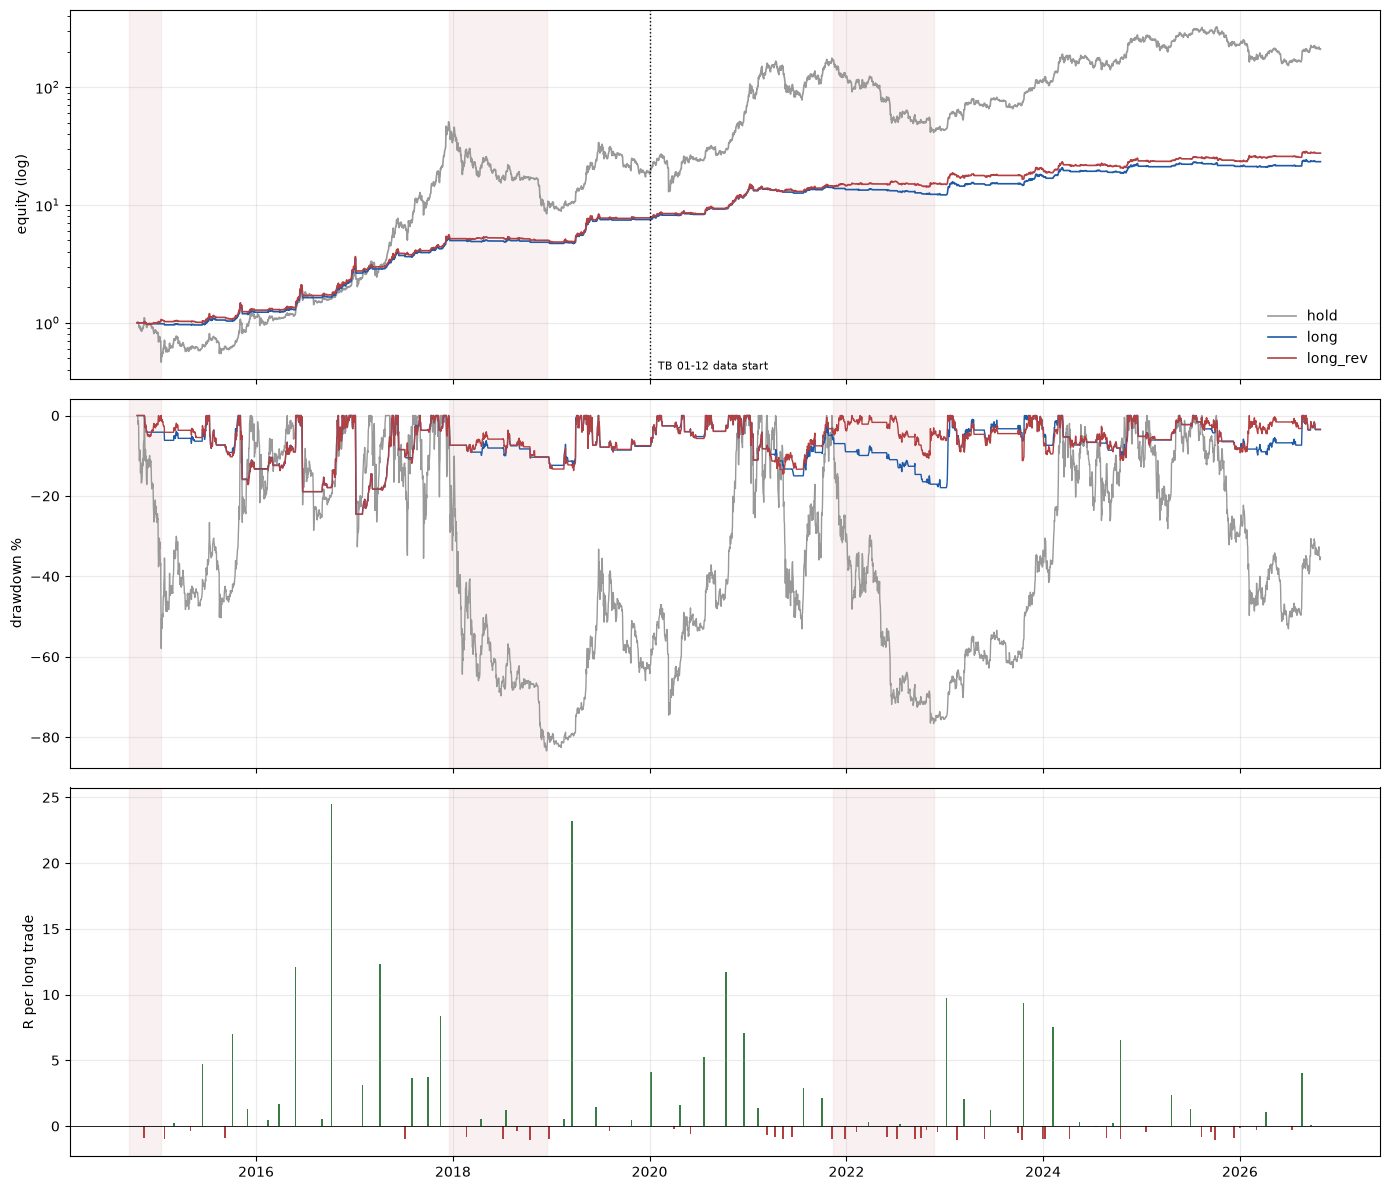

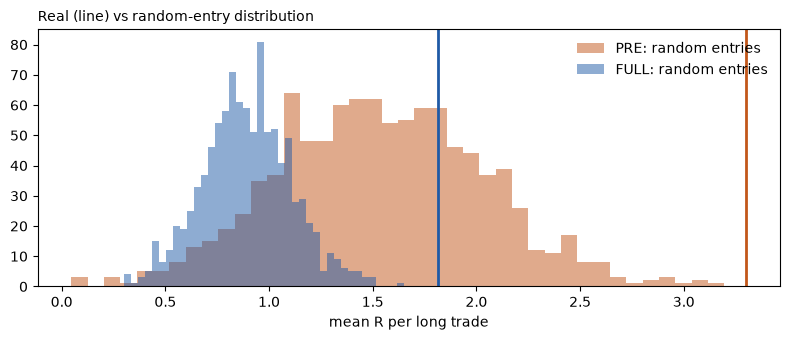

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
F = RES['FULL']
for v, col in (('hold', '0.6'), ('long', '#1f5aa6'), ('long_rev', '#b33f40')):
    axes[0].plot(F[v].index, F[v] / P.start_equity, color=col, lw=1.2, label=v)
    axes[1].plot(F[v].index, (F[v] / F[v].cummax() - 1) * 100, color=col, lw=1.0, label=v)
axes[0].set_yscale('log'); axes[0].set_ylabel('equity (log)'); axes[1].set_ylabel('drawdown %')
for a, b, lab in bh.REGIMES:
    if 'bear' in lab:
        for ax in axes:
            ax.axvspan(pd.Timestamp(a), min(pd.Timestamp(b), F['hold'].index[-1]), color='#b33f40', alpha=0.07)
axes[0].axvline(pd.Timestamp('2020-01-01'), color='k', ls=':', lw=1); axes[0].text(pd.Timestamp('2020-02-01'), axes[0].get_ylim()[0] * 1.2, 'TB 01-12 data start', fontsize=8)
T = F['trades']; lg = T[(T.kind == 'long') & ~T.open_at_end]
axes[2].bar(lg.entry, lg.R, width=6, color=np.where(lg.R > 0, '#3a7d44', '#b33f40')); axes[2].set_ylabel('R per long trade'); axes[2].axhline(0, color='k', lw=0.6)
for a in axes:
    a.grid(alpha=0.25)
axes[0].legend(frameon=False); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(8, 3.5))
for w, col in (('PRE', '#c2571a'), ('FULL', '#1f5aa6')):
    ax.hist(RES[w]['null_means'], bins=40, alpha=0.5, color=col, label=f'{w}: random entries'); ax.axvline(RES[w]['R_long'].mean(), color=col, lw=2)
ax.set_xlabel('mean R per long trade'); ax.legend(frameon=False); ax.set_title('Real (line) vs random-entry distribution', loc='left', fontsize=10)
plt.tight_layout(); plt.show()

## 5. Save

In [6]:
WIN.to_csv(OUT / '17_windows.csv'); REG.to_csv(OUT / '17_regimes.csv'); YR.to_csv(OUT / '17_yearly.csv')
RES['FULL']['trades'].to_csv(OUT / '17_trades_full.csv', index=False)
pd.DataFrame({f'{w}|{v}': RES[w][v] for w in bh.WINDOWS for v in ('long', 'long_rev', 'hold')}).to_csv(OUT / '17_curves.csv')
np.savez(OUT / '17_null.npz', **{w: RES[w]['null_means'] for w in bh.WINDOWS})
(OUT / '17_decision.json').write_text(json.dumps({'decision': DEC, 'registration': bh.registration(BP), 'synthetic': SYNTHETIC}, indent=1, default=float))
git = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], cwd=str(ROOT), capture_output=True, text=True).stdout.strip()
(OUT / '17_manifest.json').write_text(json.dumps({'version': bh.VERSION, 'git': git, 'python': platform.python_version(), 'created_utc': pd.Timestamp.now('UTC').isoformat(),
    'data': [str(DAILY.index[0].date()), str(DAILY.index[-1].date())], 'synthetic': SYNTHETIC}, indent=1))
print('saved to', OUT); print('VERDICT:', DEC['verdict'])

saved to D:\Projects\deribit_market_data\notebooks\Turtle_Breakout\17
VERDICT: TIMING_EDGE_ONLY
